In [30]:
# 1. Import Libraries


import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split



In [31]:
# 2. Load Dataset

# Load the original dataset
df_org = pd.read_csv("/content/Customer-Churn-Records.csv")

# Display dataset dimensions
print(df_org.shape)

# Display the first five rows
df_org.head()

(10000, 18)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


In [32]:
# 3. Feature Selection

# Select the six required features
features = [
    "Age",
    "NumOfProducts",
    "EstimatedSalary",
    "Balance",
    "CreditScore",
    "Tenure"
]

# Define input features and target variable
X = df_org[features]
y = df_org["Exited"]

# Check selected data
print("Features shape:", X.shape)
print("Target shape:", y.shape)

# 4. Data Quality Check

# Check missing values
print("\nMissing values:")
print(X.isnull().sum())

# Check target distribution
print("\nTarget distribution:")
print(y.value_counts())


Features shape: (10000, 6)
Target shape: (10000,)

Missing values:
Age                0
NumOfProducts      0
EstimatedSalary    0
Balance            0
CreditScore        0
Tenure             0
dtype: int64

Target distribution:
Exited
0    7962
1    2038
Name: count, dtype: int64


In [33]:

# 5. Train/Test Split

# Split data while preserving target distribution
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Verify dataset sizes
print(f"Training set: {X_train.shape}")
print(f"Testing set: {X_test.shape}")

# Verify target distribution
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))



Training set: (8000, 6)
Testing set: (2000, 6)

Training target distribution:
Exited
0    0.796
1    0.204
Name: proportion, dtype: float64

Testing target distribution:
Exited
0    0.796
1    0.204
Name: proportion, dtype: float64


In [34]:

# 6. Model Training - Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier

# Initialize the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

# Train the model
rf_model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [35]:

# 7. Model Evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Predict customer churn on test data
y_pred = rf_model.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Display evaluation metrics
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

# Display detailed classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy:  0.8370
Precision: 0.6783
Recall:    0.3824
F1 Score:  0.4890

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.95      0.90      1592
           1       0.68      0.38      0.49       408

    accuracy                           0.84      2000
   macro avg       0.77      0.67      0.70      2000
weighted avg       0.82      0.84      0.82      2000



Age                0.265218
EstimatedSalary    0.181839
CreditScore        0.171142
Balance            0.158425
NumOfProducts      0.137898
Tenure             0.085479
dtype: float64


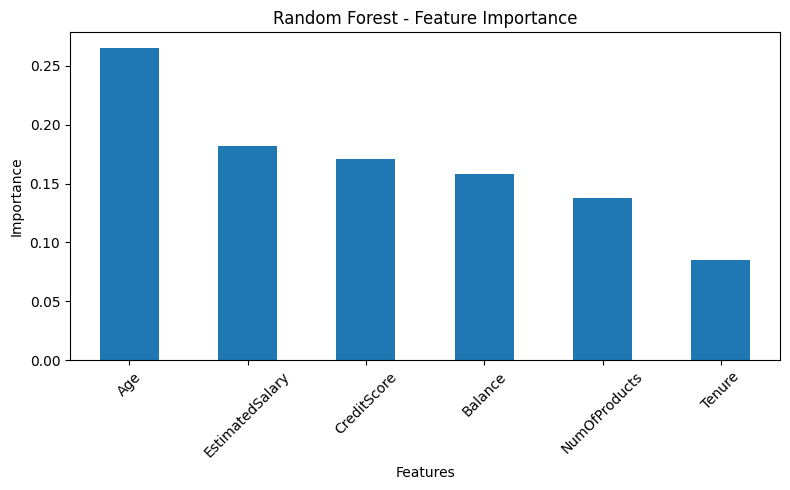

In [36]:

# 8. Feature Importance

import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

# Display feature importance
print(feature_importance)

# Visualize feature importance
feature_importance.plot(kind="bar", figsize=(8, 5))
plt.title("Random Forest - Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [37]:

# 9. Model Serialization

import pickle

# Save the trained model
with open("random_forest_model.pkl", "wb") as file:
    pickle.dump(rf_model, file)

print("Model saved successfully!")


Model saved successfully!


In [38]:

# 10. Download Trained Model

from google.colab import files

# Download the trained model
files.download("random_forest_model.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>